# Covariance and Pearson correlation

A sensitivity analysis of linear association under changes in noise, direction and measurement scale.

## Data and scope

The analysis uses 1,000 synthetic pairs generated with random seed 1. The baseline is `data1 = 20 × N(0,1) + 100` and `data2 = data1 + 10 × N(0,1) + 50`. The same observations and noise vector are retained across comparisons. No external data file is required.

## Environment

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn
print('numpy', np.__version__, 'pandas', pd.__version__, 'scipy', scipy.__version__, 'sklearn', sklearn.__version__)
results = {}

numpy 2.4.4 pandas 3.0.2 scipy 1.17.1 sklearn 1.8.0


## Baseline analysis

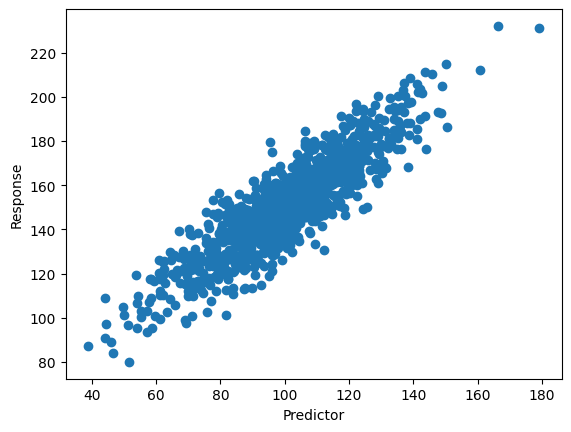

data1: mean=100.776 stdv=19.620
data2: mean=151.050 stdv=22.358
Covariance: 389.755
Pearsons correlation: 0.888


In [2]:
from numpy import mean
from numpy import std
from numpy import cov
from numpy.random import randn
from numpy.random import seed
from matplotlib import pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
seed(1)
data1 = 20 * randn(1000) + 100
data2 = data1 + (10 * randn(1000) + 50)
covariance = cov(data1, data2)
corr, _ = pearsonr(data1, data2)
plt.scatter(data1, data2)
plt.show()
print('data1: mean=%.3f stdv=%.3f' % (mean(data1), std(data1)))
print('data2: mean=%.3f stdv=%.3f' % (mean(data2), std(data2)))
print('Covariance: %.3f' % covariance[0][1])
print('Pearsons correlation: %.3f' % corr)

## Sensitivity analysis

Four cases are compared: the baseline; a noise standard deviation of 40; a negative relationship between the variables; and a tenfold rescaling of the baseline response. Sample covariance and Pearson r quantify the changes.

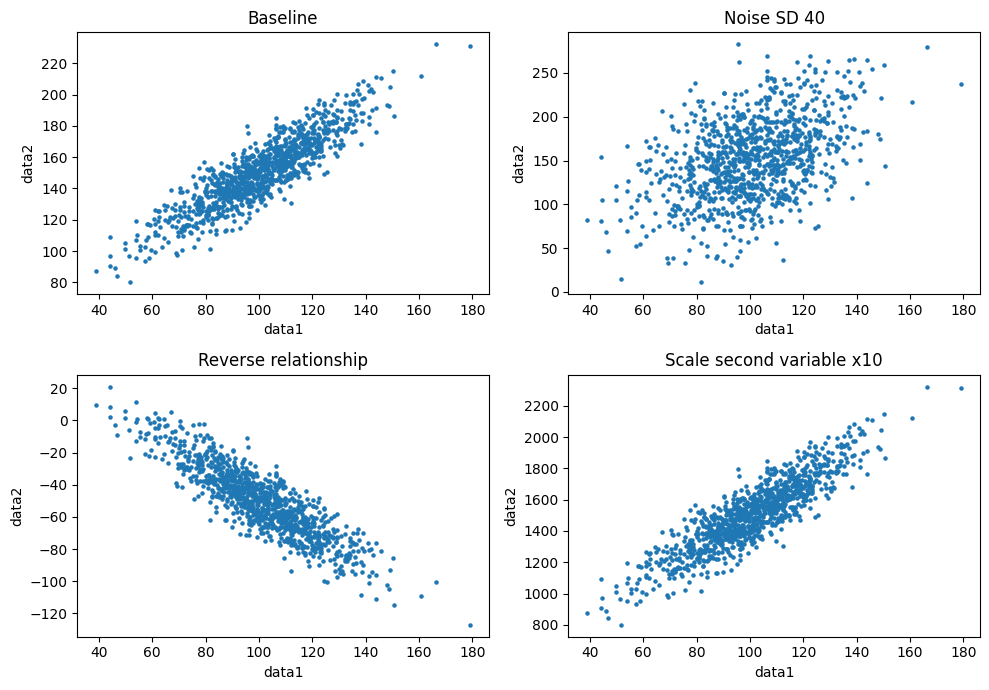

In [3]:
from scipy.stats import pearsonr, linregress
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
np.random.seed(1)
a = 20 * np.random.randn(1000) + 100
z = np.random.randn(1000)
b = a + 10 * z + 50
cases = {'Baseline': (a, b), 'Noise SD 40': (a, a + 40 * z + 50), 'Reverse relationship': (a, -a + 10 * z + 50), 'Scale second variable x10': (a, 10 * b)}
results['correlation'] = {}
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, (name, (u, v)) in zip(axes.flat, cases.items()):
    results['correlation'][name] = {'covariance': float(np.cov(u, v)[0, 1]), 'r': float(pearsonr(u, v).statistic)}
    ax.scatter(u, v, s=5)
    ax.set(title=name, xlabel='data1', ylabel='data2')
plt.tight_layout()
plt.show()

## Results

R² values describe training fit. Where reported, leave-one-out RMSE measures held-out error in response units; lower values indicate smaller errors.

In [4]:
display(pd.DataFrame.from_dict(results['correlation'], orient='index').rename(columns={'covariance': 'Sample covariance', 'r': 'Pearson r'}).round(4))

,Sample covariance,Pearson r
Baseline,389.7546,0.8876
Noise SD 40,403.0193,0.4459
Reverse relationship,-380.9114,-0.8832
Scale second variable x10,3897.5456,0.8876


## Interpretation and limitations

Increasing noise reduces Pearson r from 0.8876 to 0.4459, while covariance rises slightly because the fixed noise vector has a small positive sample covariance with the predictor. Rescaling the response multiplies covariance by ten without changing r. Reversing the relationship changes both signs. These results distinguish scale-dependent covariance from standardised linear association. Synthetic construction limits the conclusions to statistical behaviour; no causal or population-level inference is supported.

## Reproducibility

Cells were executed sequentially in an independent Python namespace. Outputs and plots are embedded, and library versions are recorded above. Analysis and editorial preparation used AI assistance.